# UTS Praktikum Certan

**Nama** : Christina Adelia Sitinjak  
**NIM** : 42324056    

## Soal 1 [30 poin]: Menganalisis dataset `users_data_cleaned.pickle`

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load and preview the data
df = pd.read_pickle('users_data_cleaned.pickle')
df.head()

,user_id,number_transactions,total_amount_usd,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,term_deposit,date_joined,device
0,9231c446-cb16-4b2b-a7f7-ddfc8b25aaf6,3.0,2143.0,58,management,married,tertiary,False,True,False,None,261,1,-1,0,None,False,1998-08-23,mobile
1,bb92765a-08de-4963-b432-496524b39157,NaN,NaN,44,technician,single,secondary,False,True,False,None,151,1,-1,0,None,False,2008-07-15,desktop
2,573de577-49ef-42b9-83da-d3cfb817b5c1,2.0,2.0,33,entrepreneur,married,secondary,False,True,True,None,76,1,-1,0,None,False,2002-06-04,mobile
3,d6b66b9d-7c8f-4257-a682-e136f640b7e3,NaN,NaN,47,blue-collar,married,None,False,True,False,None,92,1,-1,0,None,False,1995-06-29,tablet
4,fade0b20-7594-4d9a-84cd-c02f79b1b526,1.0,1.0,33,None,single,None,False,False,False,None,198,1,-1,0,None,False,1995-08-01,mobile


#### Penjelasan:

Kode di atas untuk menyiapkan semua library yang dipakai, lalu membuka file `users_data_cleaned.pickle`.

Empat baris pertama adalah proses *import*. `pandas` (disingkat `pd`) dipakai untuk mengolah data berbentuk tabel, `numpy` (disingkat `np`) untuk hitungan angka, `matplotlib.pyplot` (disingkat `plt`) untuk membuat grafik, dan `seaborn` (disingkat `sns`) untuk membuat grafik yang tampilannya lebih rapi.

Baris `df = pd.read_pickle('users_data_cleaned.pickle')` membaca file data. File berformat `.pickle` itu berbeda dengan `.csv`. Pickle adalah file yang menyimpan objek Python apa adanya, jadi tipe data tiap kolom (misalnya tanggal atau angka) ikut tersimpan dan tidak perlu ditebak ulang. Karena itu pembacaannya memakai `read_pickle`, bukan `read_csv`. Hasil bacanya disimpan dalam variabel `df` (singkatan dari *DataFrame*, yaitu tabel di pandas), dan nama `df` ini dipakai terus sampai soal terakhir.

Baris `df.head()` menampilkan 5 baris paling atas dari tabel. Tujuannya hanya untuk memastikan file terbaca dengan benar dan kita punya gambaran awal isi datanya. Dari tampilan ini terlihat ada kolom `user_id`, `number_transactions`, `total_amount_usd`, `age`, `job`, `marital`, `education`, `date_joined`, dan beberapa kolom lain seperti `housing`, `loan`, `duration`, `campaign`, dan `term_deposit`.

In [6]:
# 2. Check the shape of the data
df.shape

(45209, 19)

#### Penjelasan:

Kode di atas untuk mengetahui ukuran data, yaitu berapa banyak baris dan berapa banyak kolom yang ada di tabel.

`df.shape` mengembalikan dua angka dalam bentuk `(jumlah_baris, jumlah_kolom)`. Disini `shape` tidak memakai tanda kurung di belakangnya, karena `shape` adalah atribut (sifat) dari tabel, bukan perintah yang perlu dijalankan.

In [7]:
# 3. Check the data types 
df.dtypes

user_id                        object
number_transactions           float64
total_amount_usd              float64
age                             int64
job                            object
marital                        object
education                      object
default                          bool
housing                          bool
loan                             bool
contact                        object
duration                        int64
campaign                        int64
pdays                           int64
previous                        int64
poutcome                       object
term_deposit                     bool
date_joined            datetime64[ns]
device                         object
dtype: object

#### Penjelasan:

Kode di atas untuk melihat tipe data dari setiap kolom. Langkah ini penting karena tipe data menentukan perhitungan apa yang boleh dilakukan pada kolom tersebut. Kolom angka bisa dihitung rata-ratanya, sedangkan kolom teks tidak.

`df.dtypes` menampilkan satu baris untuk setiap kolom, berisi nama kolom dan tipe datanya.

In [8]:
# 4. Check for correlations 
df.corr(numeric_only=True)

,number_transactions,total_amount_usd,age,default,housing,loan,duration,campaign,pdays,previous,term_deposit
number_transactions,1.000000,-0.163409,-0.008813,0.138838,0.030429,0.075319,-0.017220,0.026431,-0.030751,-0.023046,-0.053390
total_amount_usd,-0.163409,1.000000,0.095839,-0.065390,-0.066857,-0.084526,0.022586,-0.017274,0.006435,0.016952,0.050785
age,-0.008813,0.095839,1.000000,-0.017875,-0.185552,-0.015641,-0.004645,0.004767,-0.023745,0.001297,0.025168
default,0.138838,-0.065390,-0.017875,1.000000,-0.006020,0.077232,-0.010017,0.016819,-0.029982,-0.018331,-0.022421
housing,0.030429,-0.066857,-0.185552,-0.006020,1.000000,0.041341,0.005041,-0.023583,0.124197,0.037087,-0.139161
loan,0.075319,-0.084526,-0.015641,0.077232,0.041341,1.000000,-0.012395,0.009972,-0.022762,-0.011048,-0.068193
duration,-0.017220,0.022586,-0.004645,-0.010017,0.005041,-0.012395,1.000000,-0.084551,-0.001549,0.001213,0.394549
campaign,0.026431,-0.017274,0.004767,0.016819,-0.023583,0.009972,-0.084551,1.000000,-0.088636,-0.032860,-0.073179
pdays,-0.030751,0.006435,-0.023745,-0.029982,0.124197,-0.022762,-0.001549,-0.088636,1.000000,0.454817,0.103616
previous,-0.023046,0.016952,0.001297,-0.018331,0.037087,-0.011048,0.001213,-0.032860,0.454817,1.000000,0.093232


#### Penjelasan:

Kode di atas untuk menghitung korelasi, yaitu ukuran seberapa kuat dua kolom saling berhubungan. Hasilnya berupa tabel yang berisi nilai korelasi untuk setiap pasangan kolom numerik.

`df.corr()` adalah perintah untuk menghitung korelasi. Tambahan `numeric_only=True` artinya hanya kolom yang berisi angka (atau benar/salah) yang ikut dihitung. Tanpa tambahan ini, pandas versi baru akan memunculkan error karena ada kolom teks seperti `job` dan `marital` yang tentu tidak bisa dikorelasikan.

In [9]:
# 5. Generate summary statistics for numerical data only
df.select_dtypes(include='number').describe()

,number_transactions,total_amount_usd,age,duration,campaign,pdays,previous
count,35210.000000,35210.000000,45209.000000,45209.000000,45209.000000,45209.000000,45209.000000
mean,3.977052,1369.417751,40.935853,258.153067,2.763897,40.199651,0.580349
std,3.814329,3063.412688,10.618653,257.525446,3.098076,100.130586,2.303489
min,1.000000,-8019.000000,18.000000,0.000000,1.000000,-1.000000,0.000000
25%,2.000000,73.000000,33.000000,103.000000,1.000000,-1.000000,0.000000
50%,3.000000,451.000000,39.000000,180.000000,2.000000,-1.000000,0.000000
75%,4.000000,1438.000000,48.000000,319.000000,3.000000,-1.000000,0.000000
max,20.000000,102127.000000,95.000000,4918.000000,63.000000,871.000000,275.000000


#### Penjelasan:

Kode di atas untuk menampilkan ringkasan statistik dari kolom-kolom yang berisi angka saja.

`df.select_dtypes(include='number')` berfungsi memilih kolom berdasarkan tipe datanya. Dengan `include='number'`, yang diambil hanya kolom angka. Kolom teks, tanggal, dan benar/salah tidak ikut. Setelah itu, `.describe()` menghitung statistik dasar untuk tiap kolom yang terpilih. Jadi dua perintah ini disambung: pilih dulu kolom angkanya, baru dihitung ringkasannya.

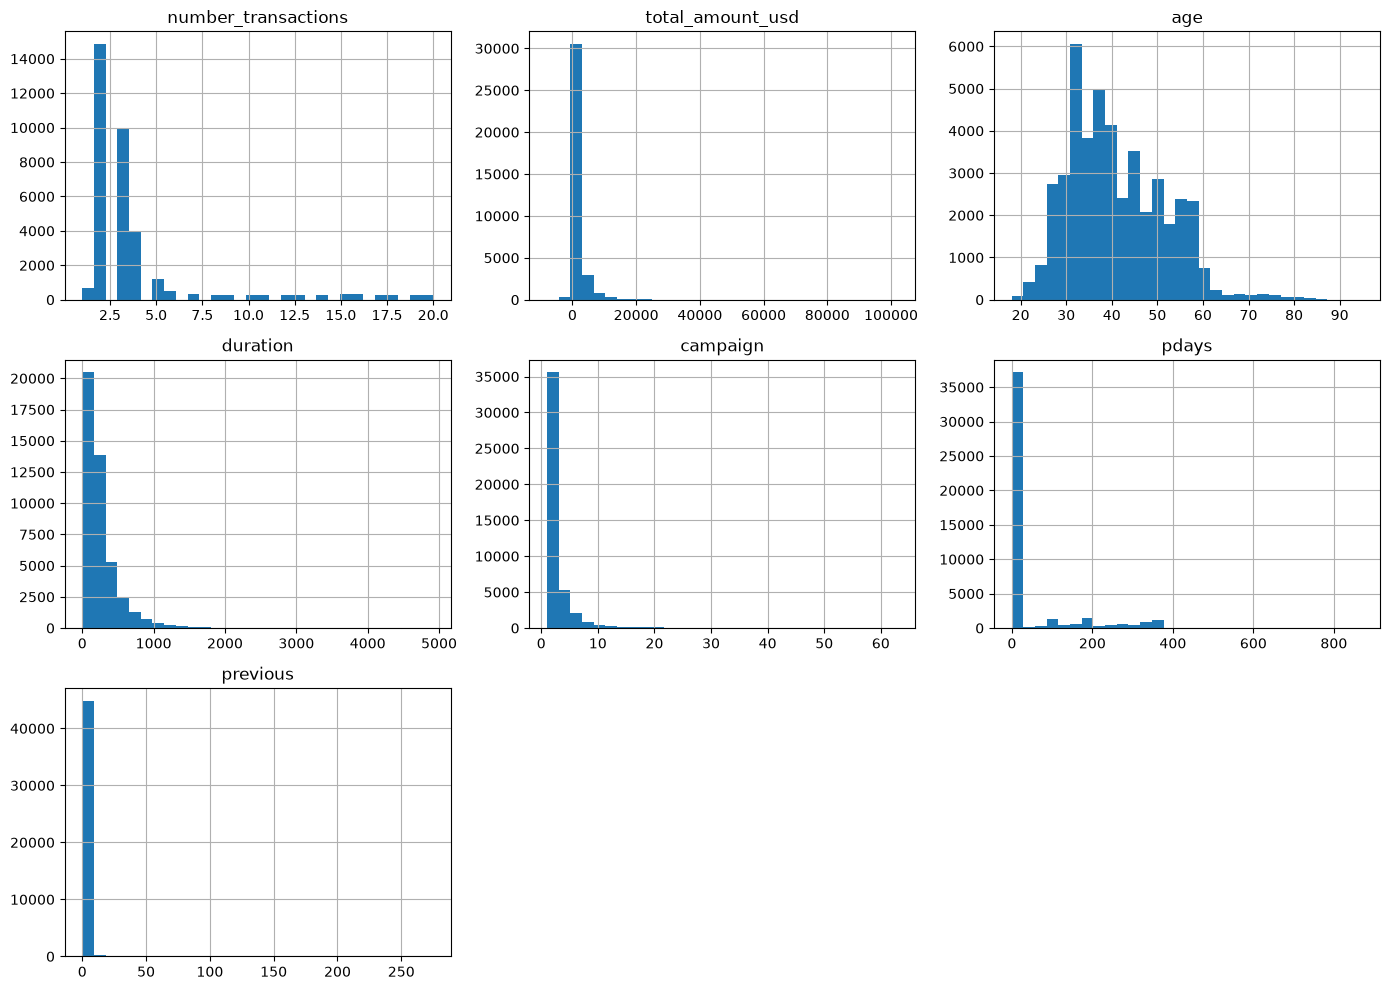

In [10]:
# 6. Plot Histograms for all numerical columns
df.select_dtypes(include='number').hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()

#### Penjelasan:

Kode di atas untuk membuat histogram dari semua kolom numerik. Histogram adalah grafik batang yang menunjukkan sebaran data, yaitu nilai mana yang paling sering muncul.

Bagian `df.select_dtypes(include='number')` memilih kolom angka seperti di langkah sebelumnya, lalu `.hist()` membuat satu histogram untuk setiap kolom tersebut sekaligus, jadi hasilnya ada 7 grafik kecil dalam satu gambar. Pengaturan `bins=30` berarti rentang nilai dibagi menjadi 30 batang. Makin banyak `bins`, makin detail bentuknya. Pengaturan `figsize=(14, 10)` mengatur ukuran gambar (lebar 14, tinggi 10) supaya tiap grafik tidak terlalu sempit.

Baris `plt.tight_layout()` merapikan jarak antar grafik supaya judul dan angka sumbu tidak saling tumpang tindih, dan `plt.show()` menampilkan gambarnya.

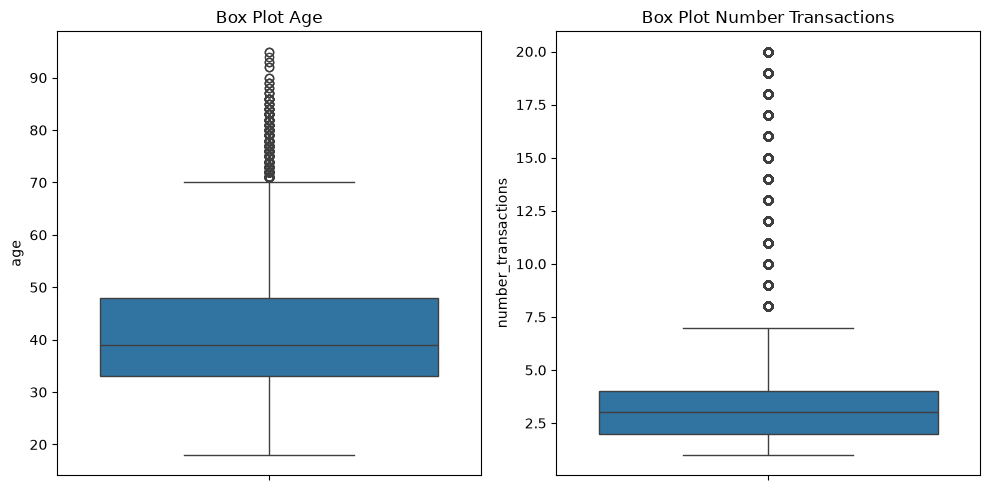

In [11]:
# 7. Generate a box plot for age, dan number_transactions
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(y=df['age'], ax=axes[0])
axes[0].set_title('Box Plot Age')

sns.boxplot(y=df['number_transactions'], ax=axes[1])
axes[1].set_title('Box Plot Number Transactions')

plt.tight_layout()
plt.show()

#### Penjelasan:

Kode di atas untuk membuat box plot dari kolom `age` dan `number_transactions`. Box plot dipakai untuk melihat sebaran data sekaligus mencari nilai yang menyimpang jauh (outlier).

Baris `fig, axes = plt.subplots(1, 2, figsize=(10, 5))` menyiapkan satu gambar berisi 1 baris dan 2 kolom grafik, jadi dua box plot bisa tampil berdampingan. Hasilnya, `axes[0]` adalah grafik kiri dan `axes[1]` adalah grafik kanan.

Selanjutnya, `sns.boxplot(y=df['age'], ax=axes[0])` menggambar box plot kolom `age` di grafik kiri. Tulisan `y=` berarti datanya digambar secara tegak. Lalu `axes[0].set_title('Box Plot Age')` memberi judul pada grafik itu. Dua baris berikutnya melakukan hal yang sama untuk `number_transactions` di grafik kanan. `plt.tight_layout()` dan `plt.show()` merapikan dan menampilkan hasilnya.

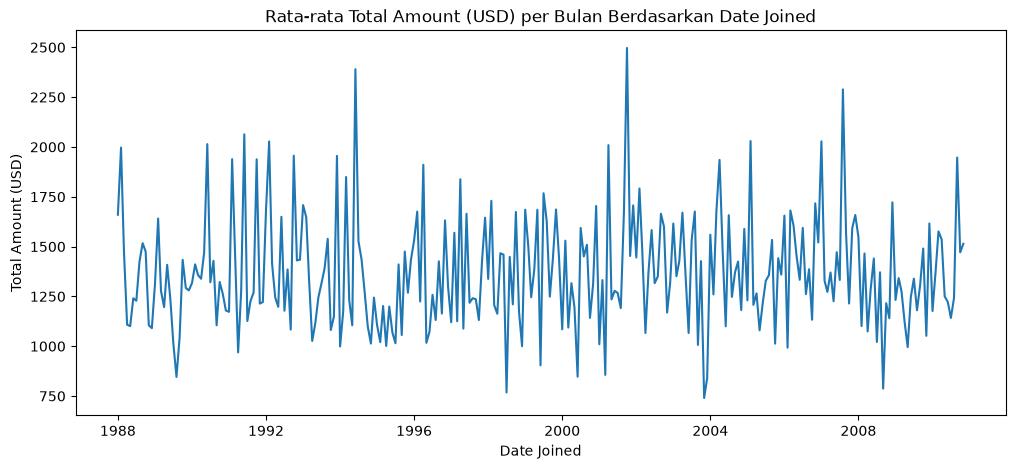

In [12]:
# 8. Generate a lineplot for date_joined to total_amount_usd
monthly = df.groupby(df['date_joined'].dt.to_period('M'))['total_amount_usd'].mean()
monthly.index = monthly.index.to_timestamp()

plt.figure(figsize=(12, 5))
sns.lineplot(x=monthly.index, y=monthly.values)
plt.title('Rata-rata Total Amount (USD) per Bulan Berdasarkan Date Joined')
plt.xlabel('Date Joined')
plt.ylabel('Total Amount (USD)')
plt.show()

#### Penjelasan:

Kode di atas untuk membuat line plot (grafik garis) yang menunjukkan bagaimana `total_amount_usd` berubah menurut `date_joined`, yaitu tanggal pengguna bergabung.

Datanya ada puluhan ribu baris, dan banyak pengguna bergabung di tanggal yang sama, sehingga kalau langsung digambar garisnya akan sangat berantakan. Karena itu datanya dirata-ratakan per bulan terlebih dahulu.

Baris `df['date_joined'].dt.to_period('M')` mengubah setiap tanggal menjadi bulannya saja (misalnya 1988-01), karena `.dt` adalah cara mengakses bagian-bagian dari kolom tanggal. Lalu `df.groupby(...)['total_amount_usd'].mean()` mengelompokkan data berdasarkan bulan itu dan menghitung rata-rata `total_amount_usd` di tiap kelompok. Hasilnya disimpan di `monthly`.

Baris `monthly.index = monthly.index.to_timestamp()` mengubah indeks yang tadinya berupa periode bulan menjadi tanggal biasa, supaya bisa dibaca oleh seaborn saat menggambar sumbu waktu.

Setelah itu, `sns.lineplot(x=monthly.index, y=monthly.values)` menggambar garisnya, dengan tanggal di sumbu x dan rata-rata jumlah uang di sumbu y. Baris `plt.title`, `plt.xlabel`, dan `plt.ylabel` memberi judul serta nama sumbu.

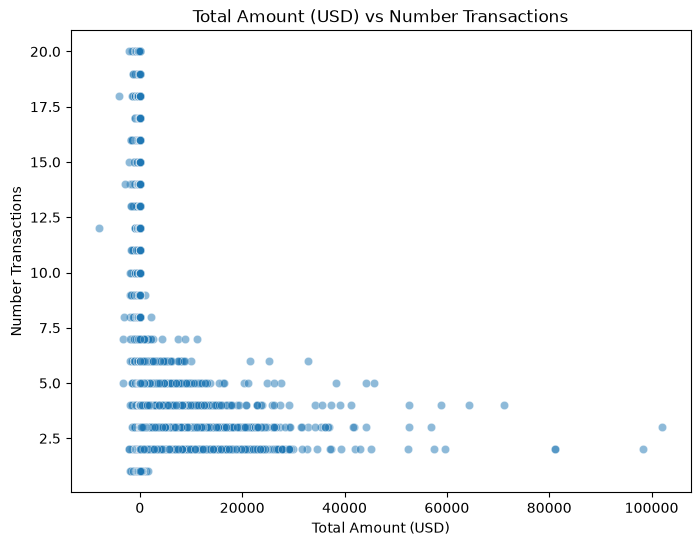

In [13]:
# 9. Generate scatter plots comparing total_amount_usd to number_transaction
plt.figure(figsize=(8, 6))
sns.scatterplot(x='total_amount_usd', y='number_transactions', data=df, alpha=0.5)
plt.title('Total Amount (USD) vs Number Transactions')
plt.xlabel('Total Amount (USD)')
plt.ylabel('Number Transactions')
plt.show()

#### Penjelasan:

Kode di atas untuk membuat scatter plot (grafik titik) yang menunjukkan hubungan antara `total_amount_usd` dan `number_transactions`. Setiap titik mewakili satu pengguna.

Baris `plt.figure(figsize=(8, 6))` mengatur ukuran gambar. Lalu `sns.scatterplot(x='total_amount_usd', y='number_transactions', data=df, alpha=0.5)` menggambar titiknya. Bagian `x=` dan `y=` menentukan kolom mana yang ditaruh di sumbu mendatar dan tegak, sedangkan `data=df` memberi tahu bahwa kolom-kolom itu diambil dari tabel `df`. Nilai `alpha=0.5` membuat titik setengah transparan, jadi di area yang titiknya menumpuk warnanya terlihat lebih pekat dan kita bisa tahu bagian mana yang padat.

Karena soalnya berbunyi "total_amount_usd terhadap number_transaction", maka `total_amount_usd` ditaruh di sumbu x dan `number_transactions` di sumbu y. Baris `plt.title`, `plt.xlabel`, dan `plt.ylabel` memberi judul serta nama sumbu.

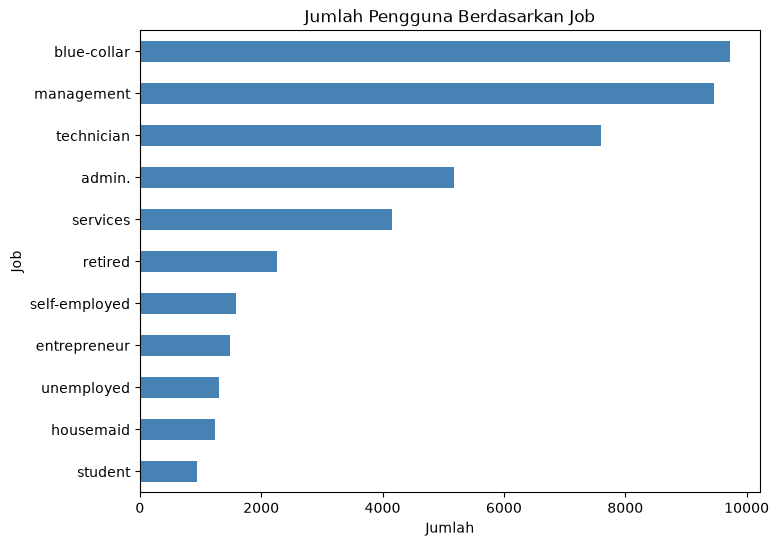

In [14]:
# 10.  Generate Horizontal bar charts for job 
plt.figure(figsize=(8, 6))
df['job'].value_counts().sort_values().plot(kind='barh', color='steelblue')
plt.title('Jumlah Pengguna Berdasarkan Job')
plt.xlabel('Jumlah')
plt.ylabel('Job')
plt.show()

#### Penjelasan:

Kode di atas untuk membuat horizontal bar chart (diagram batang mendatar) yang menunjukkan jumlah pengguna untuk setiap jenis pekerjaan (`job`).

Bagian `df['job'].value_counts()` menghitung berapa kali tiap pekerjaan muncul, hasilnya berurutan dari yang terbanyak. Lalu `.sort_values()` mengurutkan ulang dari yang terkecil ke terbesar. Urutan ini sengaja dibalik, karena grafik batang mendatar menggambar data pertama di paling bawah. Dengan begitu, batang terpanjang akan muncul di paling atas dan grafiknya lebih mudah dibaca.

Bagian `.plot(kind='barh', color='steelblue')` membuat grafiknya. Tulisan `barh` adalah singkatan dari *bar horizontal*, dan `color` mengatur warna batang. Baris `plt.title`, `plt.xlabel`, dan `plt.ylabel` memberi judul dan nama sumbu.

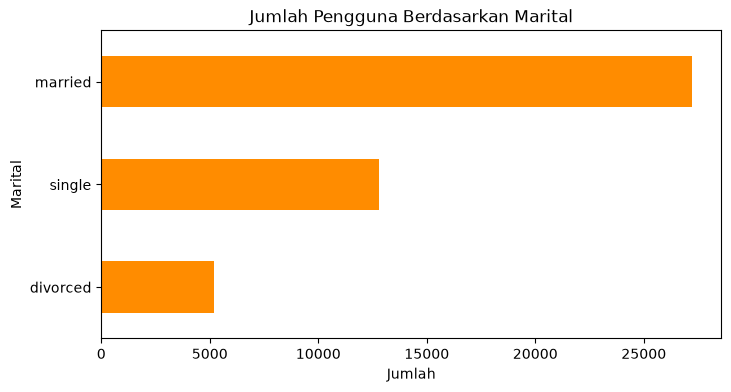

In [15]:
# 11. Generate Horizontal bar charts for marital
plt.figure(figsize=(8, 4))
df['marital'].value_counts().sort_values().plot(kind='barh', color='darkorange')
plt.title('Jumlah Pengguna Berdasarkan Marital')
plt.xlabel('Jumlah')
plt.ylabel('Marital')
plt.show()

#### Penjelasan:

Kode di atas untuk membuat horizontal bar chart yang menunjukkan jumlah pengguna berdasarkan status pernikahan (`marital`).

Cara kerjanya sama persis dengan langkah 10. `df['marital'].value_counts()` menghitung jumlah tiap status, `.sort_values()` mengurutkannya dari yang terkecil, dan `.plot(kind='barh', color='darkorange')` menggambar batang mendatar berwarna oranye tua. Ukuran gambar dibuat sedikit lebih pendek (`figsize=(8, 4)`) karena hanya ada tiga batang, jadi tidak perlu terlalu tinggi.

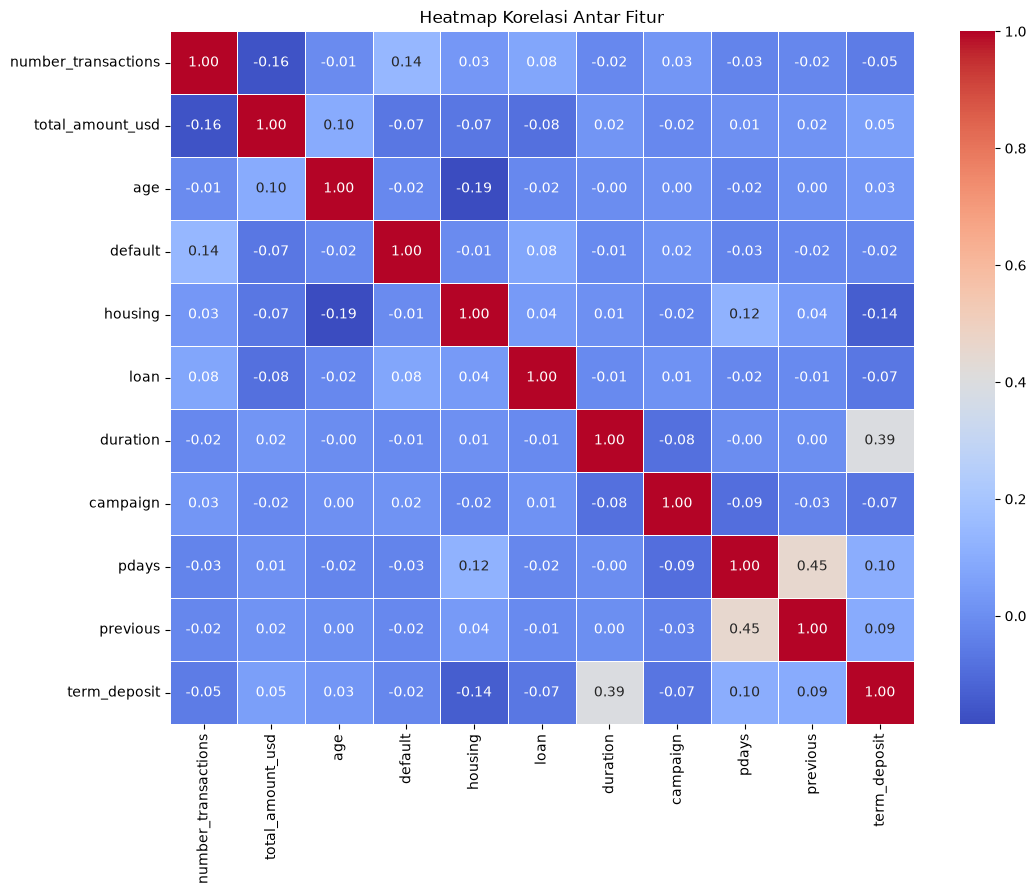

In [ ]:
# 12. Generate a heatmap for future correlations
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Heatmap Korelasi Antar Fitur')
plt.show()

#### Penjelasan:

Kode di atas untuk membuat heatmap, yaitu tabel korelasi yang diberi warna, sehingga hubungan antar kolom bisa dilihat sekilas tanpa harus membaca angkanya satu per satu.

Isi dari heatmap ini sama dengan tabel di langkah 4. Bagian `df.corr(numeric_only=True)` menghasilkan tabel korelasi, lalu `sns.heatmap(...)` mengubahnya menjadi gambar berwarna. Beberapa pengaturan yang dipakai:

`annot=True` menampilkan angka korelasi di dalam tiap kotak. `fmt='.2f'` membuat angkanya ditulis dengan 2 angka di belakang koma. `cmap='coolwarm'` memilih skema warna: biru untuk korelasi negatif, merah untuk korelasi positif, dan warna pucat untuk yang mendekati nol. `linewidths=0.5` memberi garis tipis pemisah antar kotak. Ukuran `figsize=(12, 9)` dibuat besar karena ada 11 kolom, sehingga angkanya tetap terbaca.

In [17]:
# 13. Identify Missing Values
df.isnull().sum()

user_id                    0
number_transactions     9999
total_amount_usd        9999
age                        0
job                      288
marital                    0
education               1857
default                    0
housing                    0
loan                       0
contact                13018
duration                   0
campaign                   0
pdays                      0
previous                   0
poutcome               36957
term_deposit               0
date_joined               30
device                    94
dtype: int64

#### Penjelasan:

Kode di atas untuk mencari tahu ada berapa banyak data yang kosong (*missing values*) di setiap kolom.

`df.isnull()` memeriksa setiap sel di tabel dan menghasilkan `True` jika selnya kosong, dan `False` jika ada isinya. Lalu `.sum()` menjumlahkan hasilnya per kolom. Karena `True` dihitung 1 dan `False` dihitung 0, hasil penjumlahan itu sama dengan banyaknya sel kosong di kolom tersebut.

## Soal 2: Regresi Linear pada `real_estate.csv`

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# a. Membaca file real_estate.csv 
df_sales = pd.read_csv('real_estate.csv')
df_sales

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...,...,...
409,410,2013.000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,411,2012.667,5.6,90.45606,9,24.97433,121.54310,50.0
411,412,2013.250,18.8,390.96960,7,24.97923,121.53986,40.6
412,413,2013.000,8.1,104.81010,5,24.96674,121.54067,52.5


#### Penjelasan:

Kode di atas untuk menyiapkan library yang dibutuhkan untuk regresi linear, lalu membaca file `real_estate.csv`.

Library yang di-import ada lima. `pandas` untuk mengolah tabel dan `matplotlib.pyplot` untuk grafik. Dari scikit-learn, `train_test_split` dipakai untuk membagi data menjadi data latih dan data uji, `LinearRegression` adalah model regresi linearnya, dan `r2_score` dipakai untuk menghitung nilai R-Square.

In [ ]:
# b. Menampilkan variabel dalam dataset
print("Variabel dalam dataset:", list(df_sales.columns))

X = df_sales[['BiayaPromo']]       # variabel bebas (fitur)
y = df_sales['NilaiPenjualan']     # variabel terikat (target)

print("Variabel X (fitur) :", X.columns[0])
print("Variabel y (target):", y.name)

In [ ]:
# c. Menampilkan data yang di-split (train: 80% & test: 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Jumlah data train:", len(X_train))
print("Jumlah data test :", len(X_test))

print("\n=== Data Train ===")
print(pd.concat([X_train, y_train], axis=1))

print("\n=== Data Test ===")
print(pd.concat([X_test, y_test], axis=1))

In [ ]:
# d. Memanggil LinearRegression() dan melatihnya dengan data train
model = LinearRegression()
model.fit(X_train, y_train)

In [ ]:
# e. Menampilkan hasil predict dari data test
y_pred = model.predict(X_test)

hasil_prediksi = pd.DataFrame({
    'BiayaPromo': X_test['BiayaPromo'],
    'Nilai Aktual': y_test,
    'Nilai Prediksi': y_pred.round(1)
})
hasil_prediksi

In [ ]:
# f. Grafik Nilai Penjualan berdasarkan Biaya Promosi
plt.figure(figsize=(8, 6))
plt.scatter(X, y, color='red')
plt.title('Nilai Penjualan berdasarkan Biaya Promosi')
plt.xlabel('Biaya Promosi')
plt.ylabel('Nilai Penjualan')
plt.show()

In [ ]:
# g. Garis hasil prediksi machine learning pada train set dan test set
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Train set
axes[0].scatter(X_train, y_train, color='red')
axes[0].plot(X_train, model.predict(X_train), color='blue')
axes[0].set_title('Biaya Promosi vs Nilai Penjualan (Train Set)')
axes[0].set_xlabel('Biaya Promosi')
axes[0].set_ylabel('Nilai Penjualan')

# Test set
axes[1].scatter(X_test, y_test, color='red')
axes[1].plot(X_train, model.predict(X_train), color='blue')
axes[1].set_title('Biaya Promosi vs Nilai Penjualan (Test Set)')
axes[1].set_xlabel('Biaya Promosi')

plt.tight_layout()
plt.show()

## Soal 3 (NIM Genap): K-Means Clustering pada `konsumen.csv`

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Membaca file konsumen.csv (pemisahnya titik koma)
df_konsumen = pd.read_csv('konsumen.csv', sep=';')
df_konsumen

,No,Gaji,Pengeluaran
0,1,2500,1750
1,2,3800,4200
2,3,3900,3800
3,4,4350,5500
4,5,4400,3200
5,6,5500,5450
6,7,5600,5950
7,8,5750,4100
8,9,6850,6050
9,10,6900,8500


#### Penjelasan:

Kode di atas untuk menyiapkan library yang dibutuhkan, lalu membaca file `konsumen.csv`.

Library yang di-import ada empat. `pandas` untuk mengolah tabel, `numpy` untuk hitungan angka, `matplotlib.pyplot` untuk membuat grafik, dan `KMeans` dari scikit-learn yang merupakan algoritma pengelompokan (*clustering*) yang akan dipakai.

Baris `pd.read_csv('konsumen.csv', sep=';')` membaca file CSV. Karena kolom di file ini dipisahkan titik koma, maka dipakai `sep=';'`. Hasilnya disimpan di `df_konsumen` lalu ditampilkan.

In [24]:
# 2. Menampilkan 7 row data teratas
df_konsumen.head(7)

,No,Gaji,Pengeluaran
0,1,2500,1750
1,2,3800,4200
2,3,3900,3800
3,4,4350,5500
4,5,4400,3200
5,6,5500,5450
6,7,5600,5950


#### Penjelasan:

Kode di atas untuk menampilkan 7 baris data paling atas.

Fungsi `head()` biasanya menampilkan 5 baris. Dengan menulis angka di dalam kurung, `head(7)`, jumlah baris yang ditampilkan menjadi 7 sesuai permintaan soal.

In [25]:
# 3. Menghapus kolom No
df_konsumen = df_konsumen.drop(columns='No')
df_konsumen.columns

Index(['Gaji', 'Pengeluaran'], dtype='str')

#### Penjelasan:

Kode di atas untuk menghapus kolom `No` dari tabel.

Alasan kolom ini dihapus: `No` hanya nomor urut, dan tidak punya arti untuk pengelompokan. Kalau ikut dipakai, K-Means akan ikut menghitung nomor urut sebagai ciri konsumen, dan hasil pengelompokannya jadi tidak akurat.

Baris `df_konsumen.drop(columns='No')` menghapus kolom bernama `No`. Hasilnya ditaruh kembali ke variabel `df_konsumen`, sehingga tabel yang lama tergantikan oleh tabel baru tanpa kolom `No`. Lalu `df_konsumen.columns` menampilkan nama kolom yang tersisa untuk membuktikan bahwa kolom `No` sudah hilang.

In [26]:
# 4. Menampilkan 9 row data teratas
df_konsumen.head(9)

,Gaji,Pengeluaran
0,2500,1750
1,3800,4200
2,3900,3800
3,4350,5500
4,4400,3200
5,5500,5450
6,5600,5950
7,5750,4100
8,6850,6050


#### Penjelasan:

Kode di atas untuk menampilkan 9 baris data paling atas setelah kolom `No` dihapus.

Cara kerjanya sama seperti langkah 2, hanya jumlahnya menjadi 9 lewat `head(9)`. Tujuannya untuk memastikan kolom `No` benar-benar sudah hilang dari tabel.

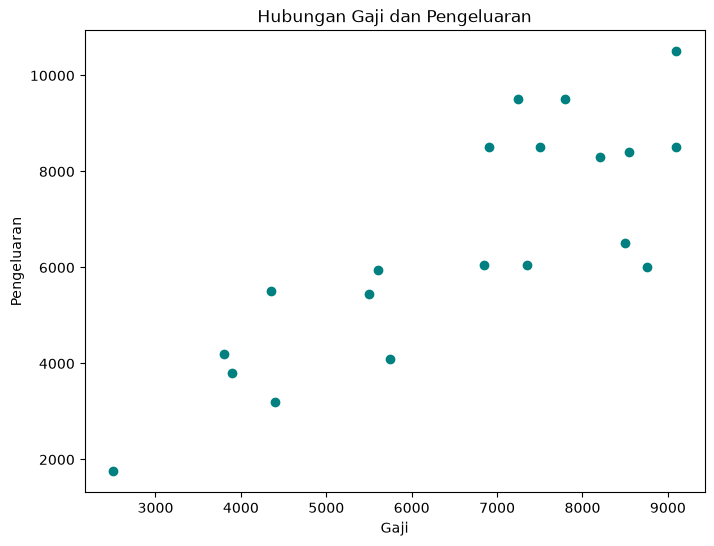

In [27]:
# 5. Menampilkan grafik hubungan gaji dan pengeluaran
plt.figure(figsize=(8, 6))
plt.scatter(df_konsumen['Gaji'], df_konsumen['Pengeluaran'], color='teal')
plt.title('Hubungan Gaji dan Pengeluaran')
plt.xlabel('Gaji')
plt.ylabel('Pengeluaran')
plt.show()

#### Penjelasan:

Kode di atas untuk membuat grafik titik yang menunjukkan hubungan antara gaji dan pengeluaran konsumen, sebelum data dikelompokkan.

Baris `plt.scatter(df_konsumen['Gaji'], df_konsumen['Pengeluaran'], color='teal')` menggambar titik untuk setiap konsumen, dengan gaji di sumbu x dan pengeluaran di sumbu y. Warnanya `teal` (hijau kebiruan). Baris `plt.title`, `plt.xlabel`, dan `plt.ylabel` memberi judul dan nama sumbu, dan `plt.figure(figsize=(8, 6))` mengatur ukuran gambar.

In [28]:
# 6. Menggunakan 2 klaster
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
kmeans.fit(df_konsumen)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 2)","[[447

#### Penjelasan:

Kode di atas untuk membuat model K-Means dengan 2 klaster, lalu melatihnya dengan data konsumen.

K-Means adalah cara mengelompokkan data tanpa label. Caranya: algoritma menentukan titik pusat awal sebanyak jumlah klaster, lalu setiap data dimasukkan ke pusat terdekat. Pusatnya kemudian dihitung ulang dari rata-rata anggotanya, dan proses ini diulang sampai pusatnya tidak banyak berubah.

Baris `KMeans(n_clusters=2, n_init=10, random_state=42)` membuat modelnya. Pengaturan `n_clusters=2` berarti data dibagi menjadi 2 klaster sesuai soal. Pengaturan `n_init=10` berarti algoritma dijalankan 10 kali dengan pusat awal yang berbeda, lalu hasil terbaik yang dipakai. Pengaturan `random_state=42` mengunci pengacakan supaya hasilnya sama setiap dijalankan.

Baris `kmeans.fit(df_konsumen)` menjalankan proses pengelompokannya memakai kolom `Gaji` dan `Pengeluaran`. Setelah itu, model menyimpan nomor klaster untuk setiap konsumen di `kmeans.labels_` dan titik pusat klaster di `kmeans.cluster_centers_`.

In [29]:
# 7. Menampilkan nilai pusat klaster
pusat_klaster = kmeans.cluster_centers_
print(pusat_klaster)

pd.DataFrame(pusat_klaster, columns=['Gaji', 'Pengeluaran'], index=['Klaster 0', 'Klaster 1'])

[[4475.   4243.75]
 [7987.5  8025.  ]]


,Gaji,Pengeluaran
Klaster 0,4475.0,4243.75
Klaster 1,7987.5,8025.00


#### Penjelasan:

Kode di atas untuk menampilkan nilai pusat klaster (*centroid*), yaitu titik tengah dari tiap kelompok konsumen.

Baris `kmeans.cluster_centers_` mengambil titik pusat itu dan disimpan di `pusat_klaster`. Isinya berbentuk array dengan dua baris (satu per klaster) dan dua kolom (gaji dan pengeluaran), sesuai urutan kolom saat model dilatih. Lalu `print(pusat_klaster)` menampilkan arraynya.

Baris terakhir membungkus array itu menjadi tabel pandas dengan nama kolom `Gaji` dan `Pengeluaran` dan nama baris `Klaster 0` dan `Klaster 1`, supaya lebih mudah dibaca.

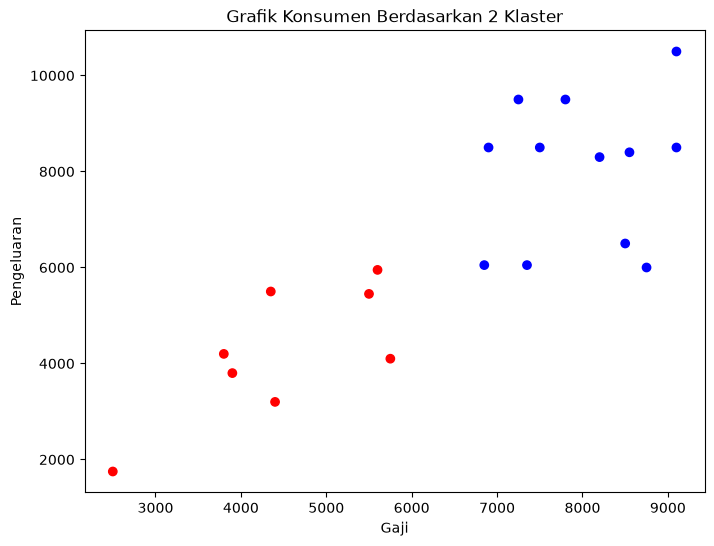

In [30]:
# 8. Grafik konsumen dengan 2 warna berbeda
warna = np.array(['red', 'blue'])[kmeans.labels_]

plt.figure(figsize=(8, 6))
plt.scatter(df_konsumen['Gaji'], df_konsumen['Pengeluaran'], c=warna)
plt.title('Grafik Konsumen Berdasarkan 2 Klaster')
plt.xlabel('Gaji')
plt.ylabel('Pengeluaran')
plt.show()

#### Penjelasan:

Kode di atas untuk menampilkan grafik konsumen di mana setiap klaster diberi warna yang berbeda.

Baris `warna = np.array(['red', 'blue'])[kmeans.labels_]` mengubah nomor klaster menjadi nama warna. Bagian `kmeans.labels_` berisi nomor klaster tiap konsumen (0 atau 1). Daftar `['red', 'blue']` dipakai seperti kamus: nomor 0 menjadi `red` dan nomor 1 menjadi `blue`. Hasilnya adalah daftar 20 warna, satu untuk tiap konsumen.

Lalu `plt.scatter(..., c=warna)` menggambar titik-titiknya, dengan parameter `c=warna` yang memberi warna tiap titik sesuai klasternya. Baris lainnya memberi judul dan nama sumbu.

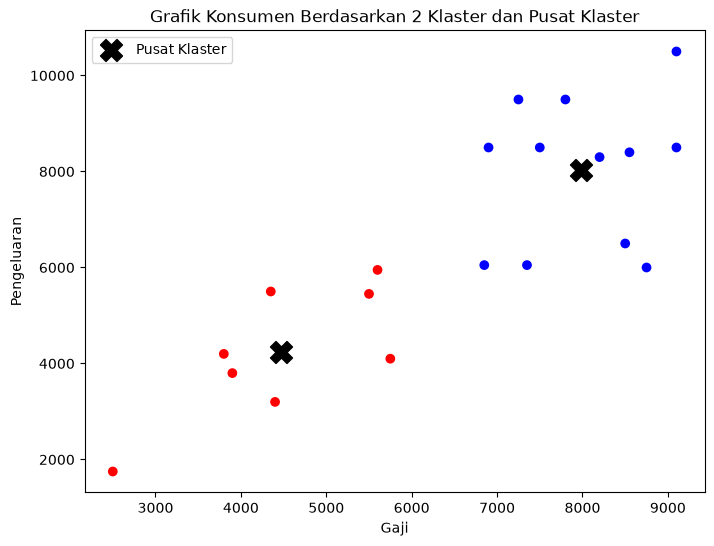

In [31]:
# 9. Grafik konsumen dengan 2 warna berbeda beserta pusat klaster
plt.figure(figsize=(8, 6))
plt.scatter(df_konsumen['Gaji'], df_konsumen['Pengeluaran'], c=warna)
plt.scatter(pusat_klaster[:, 0], pusat_klaster[:, 1],
            c='black', marker='X', s=250, label='Pusat Klaster')
plt.title('Grafik Konsumen Berdasarkan 2 Klaster dan Pusat Klaster')
plt.xlabel('Gaji')
plt.ylabel('Pengeluaran')
plt.legend()
plt.show()